## Simulated Annealing

In [3]:
# Versão para Atividade 4
import geopandas as gpd
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from shapely.geometry import Polygon

import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

import numpy as np
from matplotlib import pyplot as plt
from itertools import product
import pandas as pd

# Importa e reprojeta os arquivos
AREAS_INTERESSE = gpd.read_file('PEmSE/area_interesse.shp').to_crs('EPSG:3857')
PASSAGENS_SAR = gpd.read_file('PEmSE/passagens_SAR.shp').to_crs('EPSG:3857')

# Calcula a área em km2 segundo a projeção definida
AREAS_INTERESSE['area_km2'] = AREAS_INTERESSE.to_crs('EPSG:3857').geometry.area / 1000000
PASSAGENS_SAR['area_km2'] = PASSAGENS_SAR.to_crs('EPSG:3857').geometry.area / 1000000

WEIGHTS = [1, 1.5, 0.5] # AC, NP e SO

VERBOSE_OUTPUT = True
VERBOSE_EVALUATION = True

print(f"Number of passages: {len(PASSAGENS_SAR)}")

print(AREAS_INTERESSE)

print(AREAS_INTERESSE.sum(numeric_only=True))

Number of passages: 702
   DN  area                                           geometry       area_km2
0   1     3  POLYGON ((-6064650.101 -312930.486, -6052850.3...    3738.925071
1   1     4  POLYGON ((-5351101.095 -365993.039, -5336852.3...   28187.026492
2   1     7  POLYGON ((-5973591.897 -677640.649, -5964909.0...    7564.353656
3   1     8  POLYGON ((-6581833.982 -675625.641, -6572483.2...   39069.397812
4   1    11  POLYGON ((-6355412.972 -1060595.143, -6352296....    7764.852837
5   1    12  POLYGON ((-7080761.696 -770407.192, -7076976.8...  122662.452378
6   1    13  POLYGON ((-6066876.463 -1293839.277, -6064650....    7037.422047
DN               7.000000
area            58.000000
area_km2    216024.430292
dtype: float64


In [4]:
def extrair_metricas_tabela(best_mask):
    # 1. Filtra as passagens selecionadas pelo indivíduo
    selected_passagens = PASSAGENS_SAR.iloc[best_mask.astype(bool)].copy()
    
    if selected_passagens.empty:
        return {"area_nao_coberta_pct": 100.0, "passagens_com_sobreposicao": 0}

    # 2. Interseção com as Áreas de Interesse
    intersecao = gpd.overlay(AREAS_INTERESSE, selected_passagens, how='intersection')
    
    # 3. Cálculo da Área Não Coberta (%)
    uniao = intersecao.geometry.union_all()
    area_uniao_km2 = uniao.area / 1e6
    area_total_km2 = AREAS_INTERESSE['area_km2'].sum()
    
    area_covered = area_uniao_km2 / area_total_km2
    area_nao_coberta_pct = (1.0 - area_covered) * 100.0

    # 4. Cálculo de "Passagens com sobreposição"
    # Faz um auto-join espacial entre as passagens selecionadas para detectar interseções
    sjoin_overlaps = gpd.sjoin(
        selected_passagens, 
        selected_passagens, 
        how='inner', 
        predicate='intersects'
    )
    
    # Descarta a auto-interseção (linha com ela mesma)
    sjoin_overlaps = sjoin_overlaps[sjoin_overlaps.index != sjoin_overlaps.index_right]
    
    # Contagem de passagens únicas que se sobrepõem a pelo menos uma outra
    passagens_com_sobreposicao = sjoin_overlaps.index.nunique()
    
    print(f"Passagens com sobreposição: {passagens_com_sobreposicao}")
    print(f"Área não coberta: {area_nao_coberta_pct:.2f}%")
    
    return {
        "passagens_com_sobreposicao": passagens_com_sobreposicao,
        "area_nao_coberta_pct": area_nao_coberta_pct
    }

# indexes = np.array(PASSAGENS_SAR.index.tolist())
# # gerar máscara binária
# rng = np.random.default_rng()
# mascara_int = rng.integers(0, 2, size = len(PASSAGENS_SAR), dtype = int)
# mascara_int

def evaluate_passagens(mask_bin, VERBOSE_EVALUATION: bool = False):
    selected_passagens = PASSAGENS_SAR.iloc[mask_bin.astype(bool)]
    # Retorna zero se nenhuma passagem foi selecionada
    if selected_passagens.empty:
        return 0

    # Calcula a interseção das passagens com a área de interesse
    intersecao = gpd.overlay(
        AREAS_INTERESSE,
        selected_passagens,
        how='intersection'
    )

    # Calcula a soma das áreas de interseção
    area_intersections = intersecao.geometry.area.sum() / 1000000

    # Calcula a área total coberta, sem contar as sobreposições
    uniao = intersecao.geometry.union_all()
    area_uniao = uniao.area / 1000000

    # Calcula as métricas da solução
    overlap = (area_intersections - area_uniao) / (area_intersections + area_uniao)
    area_covered = area_uniao / AREAS_INTERESSE['area_km2'].sum()
    passages = len(selected_passagens) / len(PASSAGENS_SAR)

    # Define os pesos da função objetivo
    w1, w2, w3 = WEIGHTS

    # Calcula o score da solução
    score = w1 * area_covered - w2 * passages - w3 * overlap

    if VERBOSE_EVALUATION:
        print(
            f"Área coberta (AC): {area_covered:.6f} |",
            f"Número de passagens (NP): {len(selected_passagens)} |",
            f"Sobreposição (SO): {overlap:.6f} |",
            f"Score (Loss): {score:.6f}"
        )

    return score

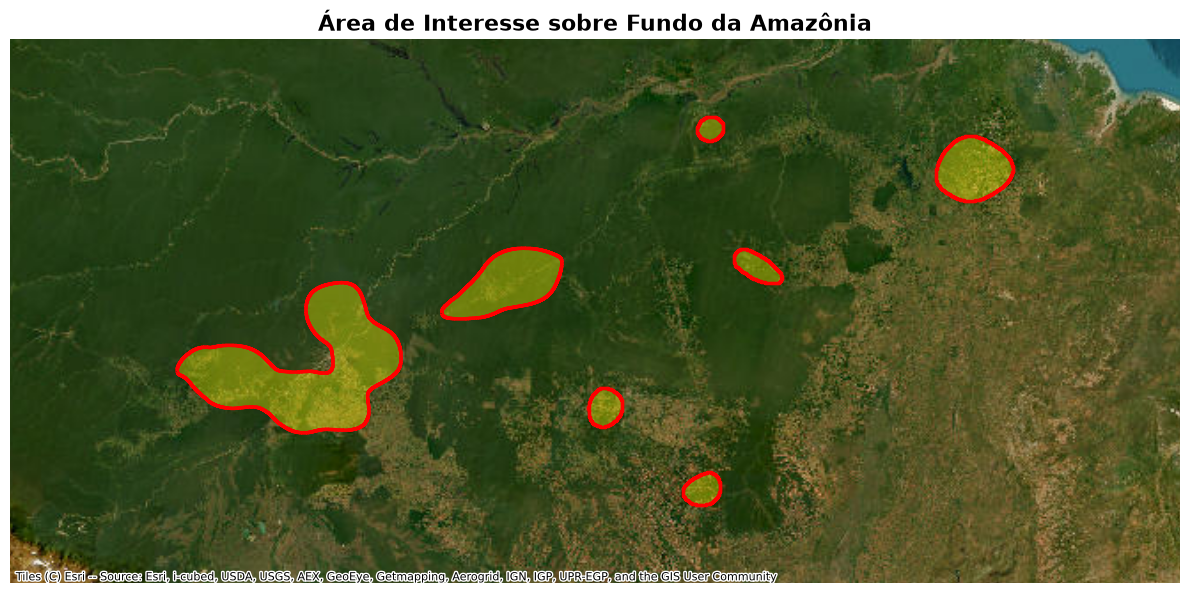

In [5]:
# Reprojetar para o sistema usado pelo mapa-base
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# Plotar a área de interesse preenchida
area_plot.plot(
    ax=ax,
    facecolor='yellow',
    edgecolor='red',
    alpha=0.35,
    linewidth=2.5,
    zorder=2
)

# Opcional: desenhar também só o contorno por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=2.5,
    zorder=3
)

ax.set_title('Área de Interesse sobre Fundo da Amazônia', fontsize=16, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('area_interesse_amazonia_fundo.png', dpi=300, bbox_inches='tight')
plt.show()

In [90]:
class BinarySimulatedAnnealing:
    def __init__(
        self,
        objective_func,
        mode='min',
        T_initial=100.0,
        T_min=1e-3, 
        alpha=0.95,
        schedule='geometric',
        movement='random',
        max_iter_per_temp=50,
        max_total_steps=100
    ):
        """
        Inicializador do Simulated Annealing Binário com múltiplos esquemas de resfriamento.

        Parâmetros:
        - objective_func: Função que recebe uma máscara binária e retorna um score.
        - mode: 'min' para minimizar ou 'max' para maximizar.
        - T_initial: Temperatura inicial (T_0).
        - T_min: Temperatura mínima de parada.
        - alpha: Taxa de resfriamento (usada no esquema geométrico).
        - schedule: Tipo de esquema de resfriamento ('geometric', 'linear', 'logarithmic').
        - max_iter_per_temp: Tentativas de vizinhança em cada nível de temperatura.
        - max_total_steps: Número máximo de passos/etapas (usado nos esquemas linear e logarítmico).
        """
        self.objective_func = objective_func
        self.mode = mode.lower()
        if self.mode not in ['min', 'max']:
            raise ValueError("O parâmetro 'mode' deve ser 'min' ou 'max'.")
        
        self.T_initial = T_initial
        self.T_min = T_min
        self.alpha = alpha
        
        self.schedule = schedule.lower()
        self.movement = movement.lower()
        
        if self.schedule not in ['geometric', 'linear', 'logarithmic']:
            raise ValueError("O esquema deve ser 'geometric', 'linear' ou 'logarithmic'.")
            
        self.max_iter_per_temp = max_iter_per_temp
        self.max_total_steps = max_total_steps

    def gen_neighbor(self, mask):
        """
        Gera um vizinho utilizando os operadores específicos para SAR:
        Adicionar, Remover ou Trocar (Swap).
        """
        neighbor_mask = mask.copy()
        n = len(neighbor_mask)
        
        ind_zeros = np.where(neighbor_mask == 0)[0]
        ind_ones = np.where(neighbor_mask == 1)[0]
        
        # Decide aleatoriamente qual movimento realizar com base no estado atual
        # Se não houver 0s ou 1s disponíveis para certas operações, ajustamos as probabilidades
        movement = self.movement
        if movement == "random":
            options = []
            if len(ind_zeros) > 0:
                options.append('add')
            if len(ind_ones) > 0:
                options.append('remove')
            if len(ind_zeros) > 0 and len(ind_ones) > 0:
                options.append('flip')
            movement = np.random.choice(options)
        
        if movement == 'add':
            # Liga um bit que estava 0 (Aumenta NP)[cite: 37, 38]
            idx = np.random.choice(ind_zeros)
            neighbor_mask[idx] = 1
            
        elif movement == 'remove':
            # Desliga um bit que estava 1 (Reduz NP)[cite: 37, 38]
            idx = np.random.choice(ind_ones)
            neighbor_mask[idx] = 0
            
        elif movement == 'flip':
            # Troca um 1 por um 0 (Mantém NP, altera quais estão ativas)[cite: 37, 38]
            idx_1 = np.random.choice(ind_ones)
            idx_0 = np.random.choice(ind_zeros)
            neighbor_mask[idx_1] = 0
            neighbor_mask[idx_0] = 1
            
        return neighbor_mask

    def optimize(self, initial_mask, seed=None):
        if seed is not None:
            np.random.seed(seed)

        T = self.T_initial
        I = 1
        K = self.max_total_steps

        current_mask = np.array(initial_mask, dtype=int)
        current_score = self.objective_func(current_mask)
        
        best_mask = current_mask.copy()
        best_score = current_score
        history = [current_score]
        T_history = []

        for k in range(K):
            # 1. Atualização da Temperatura com base no esquema escolhido[cite: 32]
            if self.schedule == 'geometric':
                # T_k = T_0 * alpha^k (ou decaimento multiplicativo T *= alpha)
                if k > 0:
                    T *= self.alpha
            elif self.schedule == 'linear':
                # T_k = T_0 * (1 - k / K)[cite: 32]
                T = self.T_initial * (1.0 - k / K)
            elif self.schedule == 'logarithmic':
                # T_k = c / ln(1 + k)[cite: 32] (usando k+1 para evitar divisão por zero no início)
                T = self.T_initial / np.log(1.0 + (k + 1))

            # Critério de parada por temperatura mínima
            if T < self.T_min:
                break

            # 2. Exploração da vizinhança na temperatura atual (L tentativas)
            for _ in range(self.max_iter_per_temp):
                # Vizinhança: Inverte um bit aleatório (Single-bit flip)
                neighbor_mask = self.gen_neighbor(current_mask)
                
                neighbor_score = self.objective_func(neighbor_mask)
                
                # Cálculo do Delta dependendo de min ou max
                if self.mode == 'min':
                    delta = neighbor_score - current_score
                else:
                    delta = current_score - neighbor_score
                
                # Critério de Aceitação de Metropolis
                # if delta <= 0 or np.random.rand() (random.randint(0, 10) / 10) < np.exp(-delta / T):
                if delta <= 0 or (random.randint(0, 10) / 10) < np.exp(-delta / T):
                    current_mask = neighbor_mask
                    current_score = neighbor_score
                    
                    # Atualiza o melhor histórico global
                    if self.mode == 'min':
                        if current_score < best_score:
                            best_mask = current_mask.copy()
                            best_score = current_score
                    else:
                        if current_score > best_score:
                            best_mask = current_mask.copy()
                            best_score = current_score

            if VERBOSE_OUTPUT:
                print(f"\n\n======> Interaction ({I}):  Temperature {T:.6f} | Current score {current_score:.6f} | Best score {best_score:.6f}")
                self.objective_func(current_mask, True)
                
            history.append(current_score)
            T_history.append(T)
            I += 1
            
        return best_mask, best_score, history, T_history

VERBOSE_OUTPUT = True

# 2. Criar uma máscara binária inicial aleatória de tamanho 20
tamanho = 700
mascara_inicial = np.random.randint(0, 1, size=tamanho)
mascara_inicial = np.concatenate((mascara_inicial, [1, 1]))
mascara_inicial


# 3. Instanciar o Simulated Annealing para MAXIMIZAÇÃO
sa = BinarySimulatedAnnealing(
    objective_func=evaluate_passagens,
    mode='max',
    T_initial=2.0,
    T_min=0.1,
    alpha=0.50,
    schedule='linear',       # Opções: 'geometric', 'linear', 'logarithmic'
    max_iter_per_temp=100,
    max_total_steps=50
)

# 4. Executar a otimização
melhor_mascara, melhor_score, historico, historico_t = sa.optimize(mascara_inicial, seed = 42)

print("\n--- Otimização Concluída ---")
print(f"Melhor Máscara:  {melhor_mascara}")
print(f"Melhor Score:    {melhor_score}")



======> Interaction (1):  Temperature 2.000000 | Current score 0.168993 | Best score 0.194750
Área coberta (AC): 0.200742 | Número de passagens (NP): 10 | Sobreposição (SO): 0.020764 | Score (Loss): 0.168993


======> Interaction (2):  Temperature 1.800000 | Current score 0.162708 | Best score 0.224987
Área coberta (AC): 0.199440 | Número de passagens (NP): 10 | Sobreposição (SO): 0.030730 | Score (Loss): 0.162708


======> Interaction (3):  Temperature 1.600000 | Current score 0.208520 | Best score 0.235484
Área coberta (AC): 0.255815 | Número de passagens (NP): 16 | Sobreposição (SO): 0.026216 | Score (Loss): 0.208520


======> Interaction (4):  Temperature 1.400000 | Current score 0.181476 | Best score 0.301726
Área coberta (AC): 0.254835 | Número de passagens (NP): 18 | Sobreposição (SO): 0.069795 | Score (Loss): 0.181476


======> Interaction (5):  Temperature 1.200000 | Current score 0.209386 | Best score 0.301726
Área coberta (AC): 0.264419 | Número de passagens (NP): 17 | Sob

In [6]:
def selecao_gulosa(alvo_cobertura=0.99, limite_passagens=70):
    """
    Heurística gulosa: seleciona passo a passo a passagem que
    adiciona o maior ganho marginal de cobertura à área de interesse,
    registrando o histórico de evolução a cada iteração.
    """
    n_dim = len(PASSAGENS_SAR)
    
    # Geometria unificada da área de interesse
    if hasattr(AREAS_INTERESSE.geometry, 'union_all'):
        area_total_geom = AREAS_INTERESSE.geometry.union_all()
    else:
        area_total_geom = unary_union(AREAS_INTERESSE.geometry.tolist())
        
    area_total_km2 = area_total_geom.area / 1_000_000

    # Pré-recorte de cada passagem contra a área de interesse
    geometrias_recortadas = []
    for geom in PASSAGENS_SAR.geometry:
        if geom is None or geom.is_empty:
            geometrias_recortadas.append(None)
        else:
            inter = geom.intersection(area_total_geom)
            geometrias_recortadas.append(None if inter.is_empty else inter)

    indices_restantes = [i for i, g in enumerate(geometrias_recortadas) if g is not None]
    selecionadas = []
    cobertura_atual_geom = None
    area_coberta_atual = 0.0

    # Estrutura para armazenar o histórico de cada etapa
    historico = {
        "etapa": [],
        "indice_passagem": [],
        "cobertura_pct": [],
        "ganho_km2": [],
        "area_acumulada_km2": []
    }

    print("Executando Seleção Gulosa prévia...")
    for etapa in range(1, min(limite_passagens, len(indices_restantes)) + 1):
        melhor_indice = None
        maior_ganho = 0.0

        for idx in indices_restantes:
            geom = geometrias_recortadas[idx]
            if cobertura_atual_geom is None:
                ganho = geom.area
            else:
                ganho = geom.difference(cobertura_atual_geom).area

            if ganho > maior_ganho:
                maior_ganho = ganho
                melhor_indice = idx

        if melhor_indice is None or maior_ganho <= 0:
            break

        selecionadas.append(melhor_indice)
        indices_restantes.remove(melhor_indice)

        geom_escolhida = geometrias_recortadas[melhor_indice]
        if cobertura_atual_geom is None:
            cobertura_atual_geom = geom_escolhida
        else:
            cobertura_atual_geom = cobertura_atual_geom.union(geom_escolhida)

        ganho_km2 = maior_ganho / 1_000_000
        area_coberta_atual += maior_ganho
        area_coberta_km2 = area_coberta_atual / 1_000_000
        cobertura_pct = min((area_coberta_km2 / area_total_km2) * 100, 100.0)

        # Registra a iteração no histórico
        historico["etapa"].append(etapa)
        historico["indice_passagem"].append(melhor_indice)
        historico["cobertura_pct"].append(cobertura_pct)
        historico["ganho_km2"].append(ganho_km2)
        historico["area_acumulada_km2"].append(area_coberta_km2)

        if (cobertura_pct / 100.0) >= alvo_cobertura:
            break

    mascara_gulosa = np.zeros(n_dim, dtype=int)
    mascara_gulosa[selecionadas] = 1
    print(f"Seleção Gulosa concluída: {len(selecionadas)} passagens selecionadas | Cobertura: {cobertura_pct:.2f}%\n")
    
    return mascara_gulosa, historico

In [101]:
mascara_gulosa, historico_guloso = selecao_gulosa(
    alvo_cobertura=0.70,
    limite_passagens=80
)

Executando Seleção Gulosa prévia...
Seleção Gulosa concluída: 25 passagens selecionadas | Cobertura: 70.79%



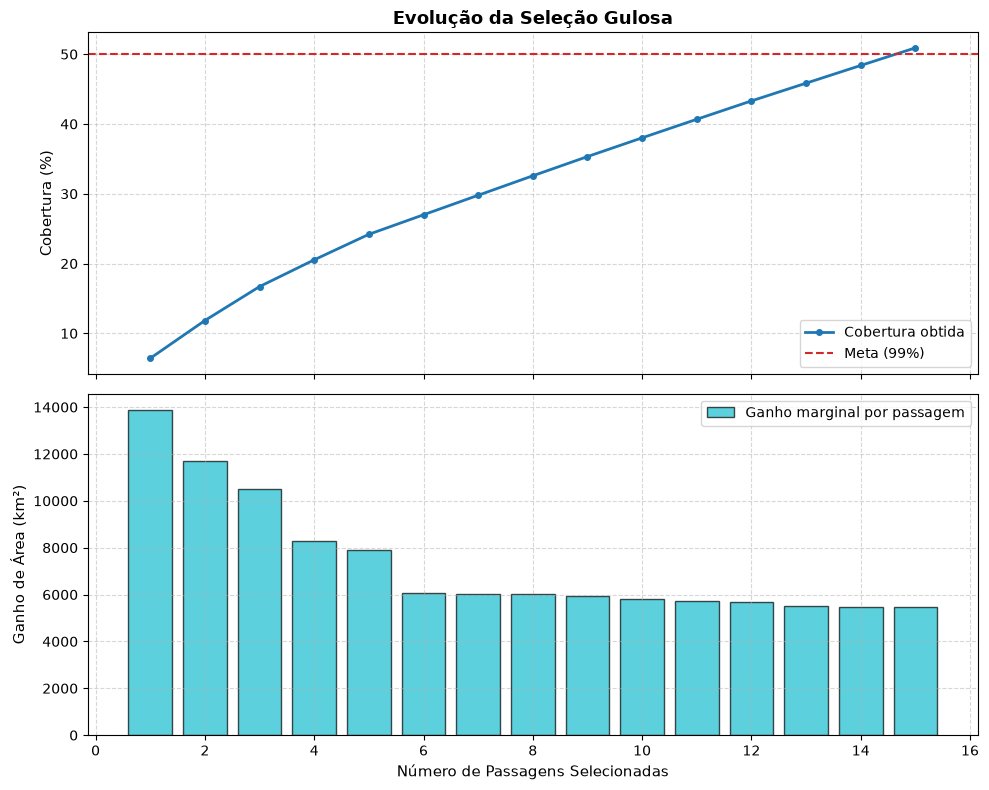

In [10]:
# 2. Gera o gráfico de evolução
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# Gráfico 1: Cobertura Acumulada (%)
ax1.plot(
    historico_guloso["etapa"],
    historico_guloso["cobertura_pct"],
    marker='o',
    color='tab:blue',
    linewidth=2,
    markersize=4,
    label='Cobertura obtida'
)
ax1.axhline(
    50,
    color='tab:red',
    linestyle='--',
    linewidth=1.5,
    label='Meta (99%)'
)
ax1.set_ylabel("Cobertura (%)", fontsize=11)
ax1.set_title("Evolução da Seleção Gulosa", fontsize=13, fontweight='bold')
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="lower right")

# Gráfico 2: Ganho Marginal de Área (km²) a cada nova passagem
ax2.bar(
    historico_guloso["etapa"],
    historico_guloso["ganho_km2"],
    color='tab:cyan',
    edgecolor='black',
    alpha=0.7,
    label='Ganho marginal por passagem'
)
ax2.set_xlabel("Número de Passagens Selecionadas", fontsize=11)
ax2.set_ylabel("Ganho de Área (km²)", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [102]:
# 3. Instanciar o Simulated Annealing para MAXIMIZAÇÃO
sa = BinarySimulatedAnnealing(
    objective_func=evaluate_passagens,
    mode='max',
    T_initial=100.0,
    T_min=0.2,
    alpha=0.001,
    schedule='logarithmic',       # Opções: 'geometric', 'linear', 'logarithmic'
    movement='random',
    max_iter_per_temp=200,
    max_total_steps=50
)

# 4. Executar a otimização
melhor_mascara, melhor_score, historico, historico_t = sa.optimize(mascara_gulosa, seed = 50)

print("\n--- Otimização Concluída ---")
print(f"Melhor Máscara:  {melhor_mascara}")
print(f"Melhor Score:    {melhor_score}")

evaluate_passagens(melhor_mascara, True)



======> Interaction (1):  Temperature 144.269504 | Current score 0.077564 | Best score 0.644318
Área coberta (AC): 0.206755 | Número de passagens (NP): 19 | Sobreposição (SO): 0.177184 | Score (Loss): 0.077564


======> Interaction (2):  Temperature 91.023923 | Current score 0.204989 | Best score 0.644318
Área coberta (AC): 0.282137 | Número de passagens (NP): 14 | Sobreposição (SO): 0.094465 | Score (Loss): 0.204989


======> Interaction (3):  Temperature 72.134752 | Current score 0.200047 | Best score 0.644318
Área coberta (AC): 0.261845 | Número de passagens (NP): 19 | Sobreposição (SO): 0.042400 | Score (Loss): 0.200047


======> Interaction (4):  Temperature 62.133493 | Current score 0.326890 | Best score 0.644318
Área coberta (AC): 0.421404 | Número de passagens (NP): 24 | Sobreposição (SO): 0.086465 | Score (Loss): 0.326890


======> Interaction (5):  Temperature 55.811063 | Current score 0.293500 | Best score 0.644318
Área coberta (AC): 0.387797 | Número de passagens (NP): 24

np.float64(0.644318189975833)

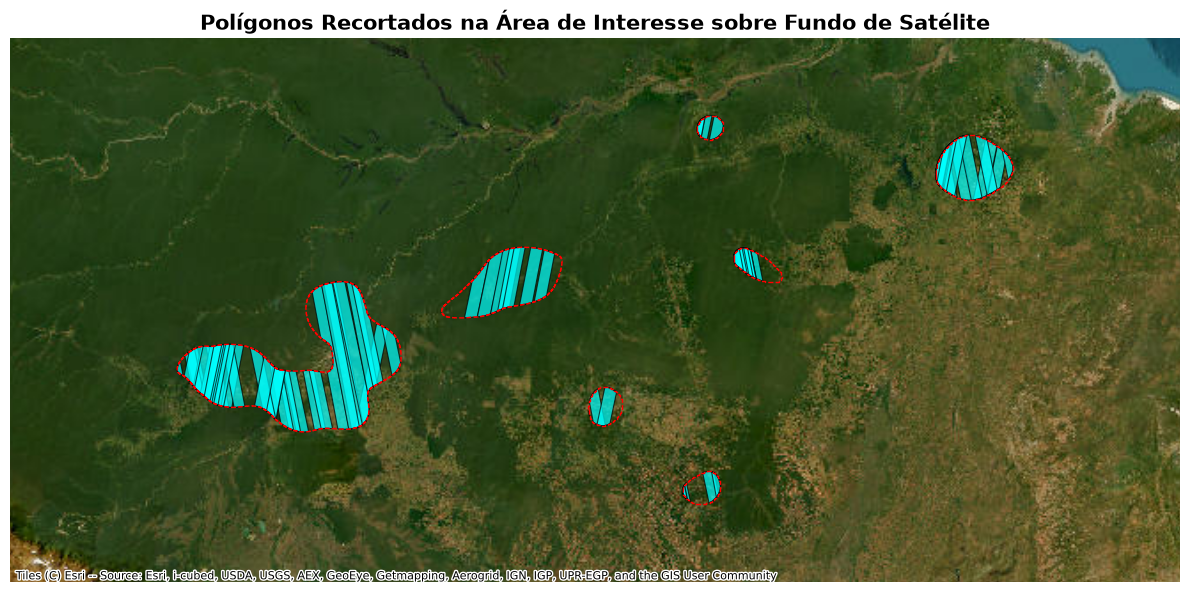

In [100]:
passagens_escolhidas = PASSAGENS_SAR.iloc[melhor_mascara.astype(bool)]

# 2. Recortar o gdf_final usando a geometria da área de interesse
gdf_recortado = passagens_escolhidas.clip(AREAS_INTERESSE)

# 3. Reprojetar ambos para EPSG:3857 (usado pelo mapa-base do contextily)
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)
gdf_recortado_plot = gdf_recortado.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# 4. Plotar o gdf final recortado
gdf_recortado_plot.plot(
    ax=ax,
    color='cyan',         # ou use 'column=nome_coluna' caso tenha classes
    alpha=0.7,
    edgecolor='black',
    linewidth=0.8,
    zorder=2,
    label='Polígonos Selecionados'
)

# 5. Desenhar o contorno da área de interesse por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=1,
    linestyle='--',
    zorder=3,
    label='Área de Interesse'
)

ax.set_title('Polígonos Recortados na Área de Interesse sobre Fundo de Satélite', fontsize=15, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('gdf_recortado_amazonia.png', dpi=300, bbox_inches='tight')
plt.show()